# Informe técnico · Calidad del aire en València

**Proyecto:** `aire-valencia-dashboard` · **Autor:** Adrián Colomo Moragues · **Última actualización:** 13/10/2026

Este notebook documenta el proyecto de principio a fin: de dónde salen los datos, cómo se procesan, qué decisiones técnicas se tomaron y qué se ha comprobado en cada fase. Todas las cifras se calculan al ejecutarlo, así que se puede reproducir desde cero.

| Fase | Content | State |
|---|---|---|
| 0 | Base funcional (ETL, SQLite, dashboard, tests) | ✅ |
| 1 | Carga y validación de los datos reales | ✅ |
| 2 | Repositorio en GitHub y CI | ✅ |
| 3 | Mejoras | ✅ 3 de 3 (escala del eje Y, control de calidad, confinamiento 2020) |
| 4 | Publicación | 🟡 preparada; falta publicar en Streamlit Cloud |

**Repositorio:** [github.com/AdrianColomoMoragues/aire-valencia-dashboard](https://github.com/AdrianColomoMoragues/aire-valencia-dashboard)

> Ejecútalo desde la raíz del proyecto, con el `.venv` activado y `pip install -r requirements-dev.txt`.

## 1. Objetivo

Construir un pipeline reproducible que transforme los datos horarios oficiales de calidad del aire de València en una base de datos consultable y un dashboard interactivo. El dashboard compara los niveles de cada contaminante con las guías de la OMS (2021).

## 2. Arquitectura

```
CSV oficial (RVVCCA) ──► ETL (aire/etl.py) ──► SQLite (data/aire.db) ──► Dashboard Streamlit (app.py)
   formato ancho          extract · transform · load      formato largo + vista diaria      Plotly
```

| Módulo | Responsabilidad |
|---|---|
| `aire/config.py` | Rutas, URL del dataset, contaminantes, guías OMS, criterio del 75 % |
| `aire/etl.py` | Lectura robusta del CSV, limpieza, paso a formato largo y registro de descartes (`TransformReport`) |
| `aire/db.py` | Esquema SQLite, carga idempotente y consultas del dashboard |
| `aire/indicadores.py` | Indicador diario (media o máx. 8 h para O₃) y superaciones |
| `aire/sample.py` | Datos sintéticos para tests y para ejecutar sin internet |

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from aire import db, etl
from aire.config import CONTAMINANTES, DB_PATH, GUIAS_OMS, MIN_HORAS_DIA, RAW_DIR

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL = "#2a78d6"

CSV = RAW_DIR / "rvvcca.-datos-horarios-valencia-2016-2021-curt-cas.csv"
print(f"CSV: {CSV.name} ({CSV.stat().st_size / 1e6:.1f} MB)")

CSV: rvvcca.-datos-horarios-valencia-2016-2021-curt-cas.csv (47.9 MB)


## 3. Fuente de datos

- **Dataset:** *Datos horarios de calidad del aire desde 2016* — Red Valenciana de Vigilancia y Control de la Contaminación Atmosférica (RVVCCA).
- **Publicado en:** portal de datos abiertos del Ajuntament de València (`opendata.vlci.valencia.es`). **Licencia:** CC BY 4.0.
- **Formato:** CSV separado por `;`, UTF-8 con BOM, una fila por estación y hora, una columna por variable (formato ancho).

In [2]:
raw = etl.read_raw(CSV)
print(f"{raw.shape[0]:,} filas × {raw.shape[1]} columnas")
raw.head(3)

449,026 filas × 27 columnas


,Fecha,Dia de la semana,Dia del mes,Hora,Estacion,PM1,PM2.5,PM10,NO,NO2,NOx,O3,SO2,CO,Velocidad del viento,Direccion del viento,NH3,C7H8,C6H6,Ruido,C8H10,Temperatura,Humedad relativa,Presion,Radiacion,Precipitacion,Velocidad maxima del viento
0,2020-01-01T00:00:00,Miércoles,1,0:00:00,Avda. Francia,NaN,77,83,16,45,69,3,7,0.2,1.3,313,NaN,NaN,NaN,NaN,NaN,6.6,89,1019,0,0,3.2
1,2020-01-01T00:00:00,Miércoles,1,1:00:00,Avda. Francia,NaN,65,70,20,37,68,3,5,0.2,1.9,315,NaN,NaN,NaN,NaN,NaN,6.2,89,1019,0,0,4.2
2,2020-01-01T00:00:00,Miércoles,1,2:00:00,Avda. Francia,NaN,47,51,16,35,61,3,5,0.1,2.2,316,NaN,NaN,NaN,NaN,NaN,5.9,90,1019,0,0,4.1


In [3]:
# Columnas: cuáles cargamos y cuáles quedan fuera del alcance actual
cargadas = list(CONTAMINANTES)
fuera = [c for c in raw.columns if c not in cargadas + ["Fecha", "Hora", "Estacion"]]
print("Contaminantes cargados:", cargadas)
print("No cargadas:", fuera)

Contaminantes cargados: ['PM2.5', 'PM10', 'NO2', 'O3', 'SO2', 'CO']
No cargadas: ['Dia de la semana', 'Dia del mes', 'PM1', 'NO', 'NOx', 'Velocidad del viento', 'Direccion del viento', 'NH3', 'C7H8', 'C6H6', 'Ruido', 'C8H10', 'Temperatura', 'Humedad relativa', 'Presion', 'Radiacion', 'Precipitacion', 'Velocidad maxima del viento']


Se cargan los seis contaminantes con guía de la OMS. El resto se deja fuera por ahora: NO y NOx se derivan del mismo analizador que NO₂, y las variables meteorológicas (viento, temperatura, humedad…) quedan para la mejora de correlación con meteorología de la Fase 3.

## 4. Fase 1 · Carga de los datos reales

### 4.1 Comprobaciones previas sobre el CSV

In [4]:
fecha_csv = etl._parse_date(raw["Fecha"])
dia_mes = pd.to_numeric(raw["Dia del mes"])
fecha, n_swap = etl._fix_day_month_swap(fecha_csv, raw["Dia del mes"])
hora = etl._parse_hour(raw["Hora"])

checks = pd.Series({
    "Fechas no interpretables": int(fecha.isna().sum()),
    "Horas no interpretables": int(hora.isna().sum()),
    "Hora mínima": int(hora.min()),
    "Hora máxima": int(hora.max()),
    "Primera fecha": fecha.min().date(),
    "Última fecha": fecha.max().date(),
    "'Fecha' no coincide con 'Dia del mes' (CSV original)": int((fecha_csv.dt.day != dia_mes).sum()),
    "Día de la semana incoherente (CSV original)": etl._weekday_mismatches(fecha_csv, raw["Dia de la semana"]),
    "Filas con día y mes intercambiados (corregidas)": n_swap,
    "Día de la semana incoherente (tras corregir)": etl._weekday_mismatches(fecha, raw["Dia de la semana"]),
    "Claves duplicadas (estación, fecha, hora)": int(
        raw.assign(f=fecha, h=hora).duplicated(["Estacion", "f", "h"]).sum()),
})
checks.to_frame("resultado")

,resultado
Fechas no interpretables,0
Horas no interpretables,0
Hora mínima,0
Hora máxima,23
Primera fecha,2016-01-01
Última fecha,2021-12-31
'Fecha' no coincide con 'Dia del mes' (CSV original),162336
Día de la semana incoherente (CSV original),147336
Filas con día y mes intercambiados (corregidas),162096
Día de la semana incoherente (tras corregir),0


Todas las fechas y horas se pueden leer, las horas van de 0 a 23 y no hay claves duplicadas. Aun así, **el CSV oficial tiene el día y el mes intercambiados en 162 096 filas (36 %)**.

**Cómo se detectó.** Al revisar el dashboard, la serie de *Valencia Centro* en 2018 solo tenía datos los días 11 y 12 de cada mes. Al contrastar `Fecha` con las columnas `Dia del mes` y `Dia de la semana` del propio CSV:

| `Fecha` en el CSV | `Dia del mes` | `Dia de la semana` | Fecha real |
|---|---|---|---|
| 2020-02-01 | 2 | Jueves | 2 de enero de 2020 (jueves) |
| 2020-01-02 | 1 | Sábado | 1 de febrero de 2020 (sábado) |

Cuando el día es 12 o menor, el portal escribe la fecha como AAAA-**DD**-**MM**. Como el intercambio solo cambia unos días por otros, no genera fechas imposibles ni duplicados, y pasa todas las comprobaciones de formato sin dar error.

**Corrección** (`_fix_day_month_swap` en `aire/etl.py`): si `Fecha` no coincide con `Dia del mes` pero el mes sí coincide, se intercambian día y mes. Después se valida con el día de la semana: **0 incoherencias tras corregir**, frente a 147 336 antes. Hay 240 filas (el 29/02/2020 de 10 estaciones) en las que el error está al revés: la fecha es correcta y es `Dia del mes` el que pone 1. La regla las deja intactas porque el mes (2) no coincide con ese 1, y el día de la semana lo confirma.

Desde la Fase 1, el ETL hace estas comprobaciones en cada ejecución y deja el resultado en el log (apartado 4.2).

In [5]:
resumen = []
for c in CONTAMINANTES:
    v = etl._to_number(raw[c])
    resumen.append({
        "contaminante": c,
        "unidad": GUIAS_OMS[c]["unidad"],
        "valores": int(v.notna().sum()),
        "% filas con dato": round(100 * v.notna().mean(), 1),
        "negativos": int((v < 0).sum()),
        "p50": v.median(), "p99": round(v.quantile(.99), 1), "máx": v.max(),
    })
pd.DataFrame(resumen).set_index("contaminante")

,unidad,valores,% filas con dato,negativos,p50,p99,máx
contaminante,,,,,,,
PM2.5,µg/m³,222412,49.5,0,9.0,48.0,193.0
PM10,µg/m³,222417,49.5,0,14.0,80.0,372.0
NO2,µg/m³,352794,78.6,0,18.0,91.8,229.0
O3,µg/m³,326129,72.6,0,53.0,111.0,172.0
SO2,µg/m³,324138,72.2,0,3.0,10.0,167.0
CO,mg/m³,150749,33.6,0,0.1,0.5,1.8


No hay valores negativos ni máximos imposibles. Los picos (PM10 = 372 µg/m³, PM2.5 = 193 µg/m³) son compatibles con episodios de intrusión de polvo sahariano o con las Fallas, así que se conservan. El filtro `valor >= 0` del ETL se mantiene como salvaguarda.

### 4.2 Ejecución del ETL

In [6]:
import logging, time
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s", force=True)

# El log muestra el desglose de descartes: filas, celdas vacías, no numéricas,
# sin clave, negativas, duplicadas y estaciones sin contaminantes.
REGENERAR = True   # ponlo a False para reutilizar data/aire.db y ahorrar ~30 s
if REGENERAR:
    DB_PATH.unlink(missing_ok=True)   # evita mezclar con datos sintéticos de --sample
    t0 = time.perf_counter()
    n = etl.run(CSV, DB_PATH)
    print(f"{n:,} mediciones en {time.perf_counter() - t0:.1f} s · {DB_PATH.stat().st_size / 1e6:.0f} MB")

INFO Leyendo rvvcca.-datos-horarios-valencia-2016-2021-curt-cas.csv (separador ';')


INFO Filas leídas: 449,026 · contaminantes: PM2.5, PM10, NO2, O3, SO2, CO


INFO Filas con fecha u hora no interpretable: 0


WARNING Filas con día y mes intercambiados (corregidas): 162,096


INFO Filas cuyo día de la semana no cuadra con la fecha: 0


...

INFO Cargadas 1,598,639 mediciones en data/aire.db


INFO Control de calidad · deriva_regional     1 episodios · 3,286 h


INFO Control de calidad · pico_aislado        6 episodios · 6 h


INFO Control de calidad · valor_atascado    306 episodios · 4,928 h


1,598,639 mediciones en 25.4 s · 175 MB


#### Lectura de los logs del ETL

Desde la Fase 1, el ETL registra en cada ejecución qué descarta y por qué (`TransformReport` en `aire/etl.py`). Con el dataset oficial:

| Concepto | Celdas | Valoración |
|---|---:|---|
| Filas con día y mes intercambiados | 162 096 filas | ⚠️ Error del CSV oficial, **corregido** (ver 4.1) |
| Filas con día de la semana incoherente tras corregir | 0 filas | ✅ La corrección es correcta |
| Celdas de contaminantes (449 026 filas × 6) | 2 694 156 | |
| Vacías | 1 095 517 | ✅ Esperado: estaciones sin ese analizador u horas sin dato |
| Texto no numérico | 0 | ✅ |
| Fecha u hora no interpretable | 0 | ✅ |
| Negativas (error de sensor) | 0 | ✅ |
| Duplicadas | 0 | ✅ |
| **Mediciones válidas** | **1 598 639 (59,3 %)** | |

**Conclusión:** el único motivo de descarte son las celdas vacías, y es normal porque no todas las estaciones miden todos los contaminantes. No se pierde ningún dato por errores de formato. El intercambio de día y mes no descarta nada, pero si no se corrigiera colocaría el 36 % de las mediciones en una fecha equivocada; por eso el log lo marca como `WARNING`. El desglose de esas celdas vacías entre huecos estructurales y huecos reales está en el apartado 4.3.

Si en una versión futura del CSV aparecen negativos, texto o fechas mal formadas, el log lo marca como `WARNING`, y el test `test_report_cuenta_cada_descarte` comprueba que cada celda se cuenta en un único motivo.

> **Importante:** si antes se ejecutó `python -m aire.etl --sample`, la base contiene estaciones sintéticas (`Centre`, `Politècnic`). Como la carga es `INSERT OR REPLACE`, no se borran solas: hay que eliminar `data/aire.db` antes de cargar los datos reales (la celda anterior ya lo hace).

### 4.3 ¿Cuántos datos se descartan?

Cada fila del CSV ancho puede dar hasta 6 mediciones. La diferencia entre ese máximo teórico y lo cargado tiene dos causas muy distintas:

- **Estructural:** la estación no tiene ese analizador (por ejemplo, Viveros no mide partículas). No es pérdida de datos.
- **Real:** la estación sí mide ese contaminante, pero esa hora el valor viene vacío (mantenimiento, calibración, avería).

In [7]:
conn = db.connect(DB_PATH)
medido = pd.read_sql_query("""
    SELECT e.nombre AS estacion, m.contaminante, COUNT(*) AS n
    FROM mediciones m JOIN estaciones e ON e.id = m.estacion_id
    GROUP BY 1, 2""", conn)

filas = raw["Estacion"].value_counts()
teorico = len(raw) * len(CONTAMINANTES)
cargado = int(medido["n"].sum())
# Una estación "tiene analizador" si aporta algún valor de ese contaminante
estructural = sum(filas[s] for s in filas.index for c in CONTAMINANTES
                  if not ((medido.estacion == s) & (medido.contaminante == c)).any())
pd.Series({
    "Máximo teórico (filas × 6)": teorico,
    "Huecos estructurales (sin analizador)": estructural,
    "Huecos reales (analizador sin dato)": teorico - estructural - cargado,
    "Mediciones cargadas": cargado,
}).map("{:,}".format).to_frame("celdas")

,celdas
Máximo teórico (filas × 6),"2,694,156"
Huecos estructurales (sin analizador),"873,654"
Huecos reales (analizador sin dato),"221,863"
Mediciones cargadas,"1,598,639"


#### Cuadre con el log del ETL

El log cuenta como **vacías** todas las celdas sin valor, sin distinguir el motivo. Este apartado las separa en dos grupos, y la suma debe coincidir exactamente con el log. Si no coincide, algo se está descartando sin quedar registrado.

In [8]:
vacias_log = sum(int(raw[c].isna().sum()) for c in CONTAMINANTES)   # lo que cuenta TransformReport
reales = teorico - estructural - cargado
cuadre = pd.Series({
    "Vacías según el log del ETL": vacias_log,
    "  · estructurales (sin analizador)": estructural,
    "  · reales (analizador sin dato)": reales,
    "Diferencia": vacias_log - estructural - reales,
}).map("{:,}".format).to_frame("celdas")
assert vacias_log == estructural + reales, "El desglose no cuadra con el log"
print(f"Huecos reales: {reales / (cargado + reales):.1%} de las horas con analizador")
cuadre

Huecos reales: 12.2% de las horas con analizador


,celdas
Vacías según el log del ETL,"1,095,517"
· estructurales (sin analizador),"873,654"
· reales (analizador sin dato),"221,863"
Diferencia,0


**Lectura:** de las 1 095 517 celdas vacías, el 80 % (873 654) son estructurales: el analizador no existe. Solo 221 863 son huecos reales, alrededor del **12 % de las horas con analizador**. No se descarta ningún valor por errores de formato, signo o duplicidad.

In [9]:
print("Estaciones del CSV sin ningún contaminante (solo meteorología):",
      sorted(set(filas.index) - set(medido.estacion)))

Estaciones del CSV sin ningún contaminante (solo meteorología): ['Consellería Meteo', 'Nazaret Meteo']


Dos estaciones del CSV (*Consellería Meteo* y *Nazaret Meteo*) son solo meteorológicas. El ETL las descarta automáticamente porque todas sus mediciones de contaminantes están vacías, así que no aparecen en el dashboard. Es el comportamiento correcto.

### 4.4 Cobertura por estación y contaminante

Porcentaje de horas con dato dentro del periodo en que cada estación estuvo activa. Las casillas vacías son analizadores que la estación no tiene.

In [10]:
activo = raw.assign(f=fecha).groupby("Estacion")["f"].agg(["min", "max"]).loc[lambda d: d.index.isin(medido.estacion)]
horas_activas = ((activo["max"] - activo["min"]).dt.days + 1) * 24
cob = medido.pivot(index="estacion", columns="contaminante", values="n")   # solo estaciones con contaminantes
cob = (cob.div(horas_activas, axis=0) * 100).round(1)[list(CONTAMINANTES)]
cob.insert(0, "periodo", activo["min"].dt.year.astype(str) + "–" + activo["max"].dt.year.astype(str))
cob

contaminante,periodo,PM2.5,PM10,NO2,O3,SO2,CO
estacion,,,,,,,
Avda. Francia,2016–2021,69.6,69.6,95.0,96.2,94.1,93.4
Bulevard Sud,2016–2021,NaN,NaN,94.1,94.3,95.9,NaN
Molí del Sol,2016–2021,81.7,81.7,80.1,81.8,78.9,74.9
Pista Silla,2016–2021,97.4,97.3,97.2,92.6,93.8,91.8
Politécnico,2016–2021,95.2,95.2,96.3,96.9,96.4,NaN
Puerto Moll Trans. Ponent,2021–2021,95.2,95.2,94.6,93.4,96.8,90.5
Puerto Valencia,2017–2020,6.5,6.5,60.0,56.4,59.7,9.2
Puerto llit antic Túria,2021–2021,45.9,45.9,44.7,44.0,44.3,31.5
Valencia Centro,2018–2021,95.4,95.4,95.4,NaN,NaN,NaN


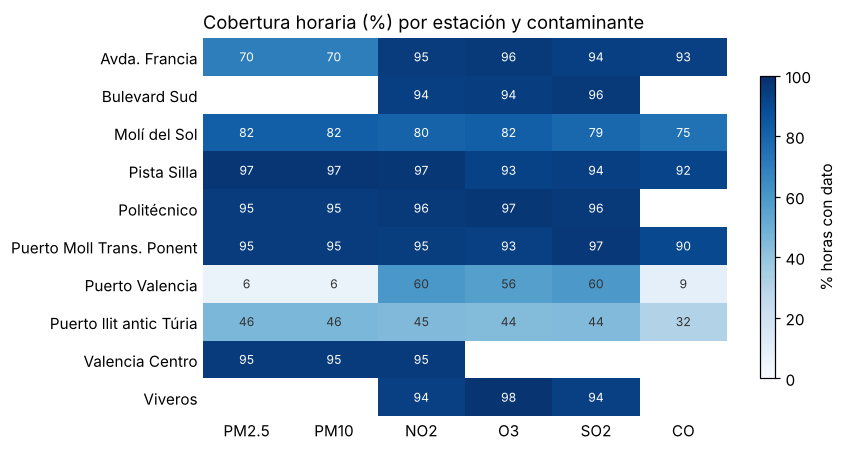

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.2))
m = cob.drop(columns="periodo").astype(float)
im = ax.imshow(m.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(m.shape[1]), m.columns)
ax.set_yticks(range(m.shape[0]), m.index)
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        v = m.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 60 else "#333")
ax.set_title("Cobertura horaria (%) por estación y contaminante", loc="left")
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
fig.colorbar(im, ax=ax, shrink=0.8, label="% horas con dato")
plt.tight_layout(); plt.show()

**Lectura:**
- Las estaciones con serie completa 2016–2021 (Avda. Francia, Bulevard Sud, Pista Silla, Politécnico, Viveros) y *Valencia Centro* (desde el 15/10/2018) superan el 93 % de cobertura en casi todo. En *Avda. Francia* las partículas bajan al ~70 % porque empiezan en 2017.
- *Molí del Sol* se queda en torno al 80 % porque **no tiene datos en todo 2018**: es un hueco real de la red, no un error del ETL.
- Las estaciones del **Puerto** cambian con el tiempo. *Puerto Valencia* (2017–2020) no tiene datos desde enero de 2019 hasta julio de 2020, y PM y CO solo se midieron en 2020. En 2021 la sustituyen *Moll Trans. Ponent* y *llit antic Túria*; esta última tiene filas desde enero, pero no da datos hasta el 15/07/2021 (~45 %).
- En conjunto, los huecos reales suponen alrededor del **12 %** de las horas en que había analizador (221 863 de 1 820 502).
- Consecuencia para el análisis: **las comparaciones entre estaciones deben hacerse en el periodo común**; si no, las medias de las estaciones del puerto no serán comparables.


In [12]:
diarias = pd.read_sql_query("SELECT estacion, contaminante, n_horas FROM medias_diarias", conn)
validos = (diarias.assign(valido=diarias.n_horas >= MIN_HORAS_DIA)
           .groupby("contaminante")["valido"].agg(dias="size", pct_validos="mean"))
validos["pct_validos"] = (validos["pct_validos"] * 100).round(1)
validos.loc[list(CONTAMINANTES)]

,dias,pct_validos
contaminante,,
PM2.5,9397,98.1
PM10,9397,98.1
NO2,15074,97.2
O3,13843,97.9
SO2,13755,97.9
CO,6478,95.9


### 4.6 Primer vistazo frente a las guías de la OMS

Porcentaje de días válidos en que el indicador diario supera la guía de la OMS (2021), con todas las estaciones juntas. Para O₃ se usa el máximo diario de la media móvil de 8 h; para el resto, la media diaria.

In [13]:
from aire.indicadores import daily_indicator

estaciones = db.list_stations(conn)
d0, d1 = db.date_range(conn)
filas_sup = []
for c in CONTAMINANTES:
    diario = db.daily_means(conn, c, estaciones, d0, d1)
    horario = db.hourly_values(conn, c, estaciones, d0, d1) if c == "O3" else None
    ind = daily_indicator(c, diario, horario)
    guia = GUIAS_OMS[c]["valor"]
    filas_sup.append({"contaminante": c, "guía OMS": f'{guia} {GUIAS_OMS[c]["unidad"]}',
                      "días válidos": len(ind),
                      "% días > guía": round(100 * (ind["valor"] > guia).mean(), 1)})
sup = pd.DataFrame(filas_sup).set_index("contaminante")
sup

,guía OMS,días válidos,% días > guía
contaminante,,,
PM2.5,15 µg/m³,9217,25.4
PM10,45 µg/m³,9217,3.7
NO2,25 µg/m³,14648,41.3
O3,100 µg/m³,13835,8.1
SO2,40 µg/m³,13460,0.0
CO,4 mg/m³,6215,0.0


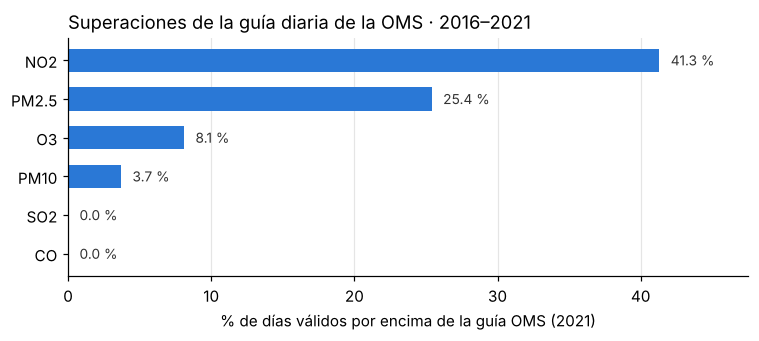

In [14]:
s = sup["% días > guía"].sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(s.index, s.values, color=AZUL, height=0.6)
for y, v in enumerate(s.values):
    ax.text(v + 0.8, y, f"{v:.1f} %", va="center", fontsize=9, color="#333")
ax.set_xlabel("% de días válidos por encima de la guía OMS (2021)")
ax.set_title("Superaciones de la guía diaria de la OMS · 2016–2021", loc="left")
ax.grid(axis="x", color="#e5e5e5"); ax.set_axisbelow(True)
ax.set_xlim(0, max(s.max() * 1.15, 5))
plt.tight_layout(); plt.show()

**Lectura:** el NO₂ es el contaminante más problemático: en el 41 % de los días válidos la media supera la guía diaria de la OMS. Le siguen las PM2.5 (25 %). El SO₂ y el CO no la superan nunca. Es un primer vistazo agregado: el detalle por estación y año está en el dashboard.

### 4.7 Revisión visual del dashboard

Revisión hecha con `streamlit run app.py` sobre los datos reales **con las fechas ya corregidas** (base regenerada; los KPI del dashboard coinciden con los de este notebook, p. ej. O₃: 1 121 días, 8,1 %), con todas las estaciones y todo el periodo 2016–2021.

**Lo que tiene sentido:**
- **Estaciones:** salen las 10 con contaminantes, cada una con su color. Para CO solo aparecen las 6 que lo miden (Avda. Francia, Molí del Sol, Pista Silla y las tres del Puerto), que es lo correcto.
- **Fechas:** el selector va del 01/01/2016 al 31/12/2021.
- **NO₂:** el 41,3 % de los días supera la guía (6 047 días), igual que en el apartado 4.6. Por estaciones, el ranking es coherente con el tráfico: *Pista Silla* (31,1 µg/m³) y *Bulevard Sud* (29,3) arriba, *Politécnico* (16,8) y *Molí del Sol* (19,2), más periféricas, abajo.
- **Perfil horario:** el NO₂ y el CO muestran dos picos en días laborables, entre las 7 y las 9 h y entre las 19 y las 22 h, mucho más suaves el fin de semana. Es la huella típica del tráfico.
- **CO:** valores de 0,1–0,2 mg/m³, muy lejos de la guía de 4 mg/m³; 0 días por encima.

**Lectura por contaminante:**

| Contaminante | % días > guía OMS | Patrón horario y semanal | Estaciones |
|---|---:|---|---|
| **NO₂** | 41,3 % | Doble pico de tráfico: de 7 a 9 h y de 19 a 22 h en días laborables; fin de semana mucho más bajo | Más alto en las de tráfico (Pista Silla, Bulevard Sud), más bajo en Politécnico |
| **O₃** | 8,1 % | Patrón **inverso**: mínimo hacia las 7 h y máximo entre las 12 y las 17 h; más alto el fin de semana. Ciclo anual muy marcado, con máximos en primavera y verano | Más alto en las periféricas y el puerto (Moll Trans. Ponent, Politécnico) y más bajo en Pista Silla |
| **PM2.5** | 25,4 % | Más alto de noche y en el pico de la mañana; sube hacia el viernes y el sábado por la noche y baja el domingo por la mañana | **Molí del Sol** es la más alta todos los años (~15 µg/m³ frente a ~10 en el resto) y en todos los meses |
| **PM10** | 3,7 % | Pico de mañana en días laborables (resuspensión por el tráfico) | Episodios puntuales muy altos (ver abajo) |
| **SO₂** | 0,0 % | Pico de mañana en días laborables, entre las 7 y las 10 h | Media de 3,8 µg/m³, muy lejos de la guía (40) en todas |
| **CO** | 0,0 % | Mismo doble pico que el NO₂ | Muy lejos de la guía en todas |

El O₃ y el NO₂ se comportan como era de esperar. El O₃ se forma con la radiación solar, y en las calles con mucho tráfico el monóxido de nitrógeno (NO) lo destruye. Por eso es más alto por la tarde, en fin de semana y lejos del tráfico, justo al revés que el NO₂. Que el dashboard reproduzca este comportamiento conocido de la química atmosférica es una buena prueba de que los datos y los cálculos son coherentes.

**Primer vistazo al confinamiento de 2020.** La caída del NO₂ se ve a simple vista en la serie. En abril, la media de todas las estaciones fue de **8,9 µg/m³ en 2020**, frente a 20–34 µg/m³ en los años 2016–2019 y 16,9 en 2021. Se analizará con más rigor en la Fase 3: en el periodo común, comparando con la misma época de otros años y teniendo en cuenta la meteorología.

**Episodios y datos que conviene investigar (Fase 3):**
- **O₃ de Puerto Valencia en la segunda mitad de 2018 (posible fallo del sensor).** En el tercer trimestre su media es de 33 µg/m³, frente a 58–66 en las demás estaciones, y en el cuarto baja a 22 (32–38 en el resto). En pleno verano el ozono debería estar en su máximo. Su NO₂ en las mismas fechas es normal, así que el problema parece del analizador de ozono, en los meses previos a que la estación deje de medir (enero de 2019). Además hay 40 horas con un valor exacto de 1,0, que parece un valor de suelo del sensor. → *Resuelto en la Fase 3:* la regla de deriva regional lo detecta automáticamente (ver Mejora 2).
- **PM10, 28/02/2020, Avda. Francia:** media diaria de 214 µg/m³ (máximo horario de 322), el peor día de toda la serie. Es compatible con una intrusión de polvo africano, pero no está confirmado.
- **PM10, 17–23/11/2017, Pista Silla:** una semana con medias de 105–161 µg/m³ que no aparece en el resto de estaciones, así que probablemente es un foco local (obras, por ejemplo).
- **PM2.5 en Molí del Sol:** el nivel es más alto de forma sistemática, no por episodios sueltos. Podría haber una fuente local, como quemas agrícolas en la huerta.
- **Puerto Valencia en PM:** su media (6–9 µg/m³) no es comparable con las demás, porque solo midió partículas en 2020 y con un 6 % de cobertura.

**Incidencias encontradas:**
1. **Líneas que unían huecos.** La serie de NO₂ dibujaba tramos rectos sobre periodos sin datos (Molí del Sol en 2018, Puerto Valencia en 2019–2020). Además, la media móvil de 7 días contaba 7 *filas*, no 7 *días*, así que podía mezclar valores separados por meses. *Corregido:* `serie_diaria_continua` (en `aire/indicadores.py`) rellena los días sin dato con NaN para que la línea se corte, y suaviza con una ventana de 7 días de calendario. Lo cubre `test_serie_continua_corta_la_linea_en_los_huecos`.
2. **Fechas con día y mes intercambiados.** Se detectó por el patrón raro de *Valencia Centro* en 2018 (ver 4.1). *Corregido en el ETL.* Además de mover fechas, deformaba el perfil semanal, porque el 36 % de las filas estaba asignado a otro día de la semana. Con la base antigua, el mapa de calor de PM2.5 mostraba un "miércoles de madrugada" anómalo. Con la base regenerada ha desaparecido; *comprobado en el dashboard*: ahora la PM2.5 nocturna sube hacia el viernes y el sábado y baja el domingo. **Importante:** después de corregir el ETL hay que regenerar `aire.db` y reiniciar Streamlit, porque `st.cache_data` guarda los resultados anteriores.
3. **Escala del eje en CO y SO₂ (mejora pendiente).** El eje Y se estira hasta la línea de la guía, así que con niveles tan bajos las series quedan aplastadas contra el cero. Se apunta para la Fase 3.

## 5. Decisiones técnicas

| Decisión | Motivo |
|---|---|
| **Formato largo** (`estacion, fecha_hora, contaminante, valor`) | Una sola consulta sirve para cualquier contaminante; añadir uno nuevo no cambia el esquema; no se guardan miles de `NULL` de analizadores inexistentes. |
| **`INSERT OR REPLACE`** con clave primaria `(estacion_id, fecha_hora, contaminante)` | La carga es idempotente: relanzar el ETL no duplica filas y una versión corregida del CSV sobrescribe los valores antiguos. |
| **Vista `medias_diarias`** con `n_horas` | La agregación diaria vive en SQL y el criterio del 75 % se aplica en la consulta. |
| **Criterio del 75 % (≥ 18 h)** | Estándar de la normativa europea para considerar representativa una media diaria. |
| **O₃ con máximo diario de la media móvil de 8 h** | Es la métrica que define la OMS para el ozono, que tiene un ciclo diario muy marcado (pico de tarde). |
| **Descartar negativos y vacíos** | Los negativos son errores de sensor; los vacíos no son ceros. |
| **Fecha reconstruida con `Dia del mes` y validada con `Dia de la semana`** | El CSV oficial intercambia día y mes cuando el día es 12 o menor. Las columnas redundantes del propio fichero permiten detectarlo y corregirlo sin suposiciones, y el día de la semana sirve como comprobación independiente (0 incoherencias tras corregir). |
| **Serie diaria continua en los gráficos** | Un día sin dato es un hueco y no debe dibujarse como una recta. La media móvil va por días de calendario (`rolling("7D")`), no por filas. |
| **Registro de descartes en el log** (`TransformReport`) | Cada celda descartada se cuenta en un único motivo, y la suma cuadra con el total. Así se audita cada carga sin abrir un notebook, y un cambio de formato en el CSV salta como `WARNING` en vez de perder datos en silencio. Lo cubre `test_report_cuenta_cada_descarte`. |
| **Separador, decimales y tildes detectados automáticamente** | El CSV oficial ha cambiado de formato entre versiones; el ETL tolera `;`/`,`, coma decimal y `Estación`/`Estacion`. |

## 6. Verificación de la Fase 1

| Comprobación | Resultado |
|---|---|
| ETL con el dataset oficial | ✅ 449 026 filas → 1 598 639 mediciones (~176 MB), ~30 s |
| Logs del ETL | ✅ solo se descartan celdas vacías (1 095 517); 0 negativas, 0 no numéricas, 0 duplicadas |
| Formatos de fecha y hora | ⚠️→✅ 162 096 filas con día y mes intercambiados, corregidas y validadas con el día de la semana |
| Duplicados y negativos | ✅ ninguno |
| Estaciones | ✅ 10 con contaminantes, 2 solo meteorológicas (excluidas) |
| Rango temporal | ✅ 2016-01-01 → 2021-12-31 |
| Revisión visual del dashboard | ✅ estaciones, fechas y valores coherentes (ver 4.7) |
| Tests (`pytest -q`) | ✅ 12/12 |

### Incidencias encontradas
1. **Día y mes intercambiados en el CSV oficial (crítica).** El 36 % de las filas tenía la fecha mal, sin que ninguna comprobación de formato lo detectara. *Corregido* en el ETL (ver 4.1). Es el hallazgo más importante de la fase: un dato puede tener un formato perfecto y aun así estar mal.
2. **Colores del dashboard repetidos.** `PALETA` en `app.py` tenía 8 colores y hay 10 estaciones, así que dos parejas compartían color. *Corregido:* la paleta tiene ahora 10 colores, validados para daltonismo.
3. **Mezcla con datos sintéticos.** Si `aire.db` se creó antes con `--sample`, las estaciones sintéticas se quedan. *Mitigación:* borrar `data/aire.db` antes de cargar (documentado en el README).
4. **Logs poco informativos.** El ETL solo indicaba "filas → mediciones", sin decir qué se descartaba ni por qué. *Corregido:* `TransformReport` desglosa los descartes y marca como `WARNING` los que indican un problema.
5. **El gráfico unía huecos.** *Corregido* (ver 4.7).
6. **Periodos distintos por estación.** No es un error, pero obliga a comparar en el periodo común. *Pendiente* para la Fase 3.

### Estado de la Fase 1
- [x] ETL con el dataset oficial
- [x] Revisión de los logs: 0 fechas u horas inválidas, 0 negativos, 0 duplicados; solo se descartan celdas vacías
- [x] Formatos de fecha y hora revisados: el parser lee bien, pero el CSV intercambia día y mes en 162 096 filas → corregido con `_fix_day_month_swap` + test
- [x] Revisión visual en el dashboard: estaciones, fechas (2016–2021) y valores (ver 4.7)

## 6.2 Verificación de la Fase 2 · Repositorio en GitHub y CI

| Comprobación | Resultado |
|---|---|
| Repositorio público `aire-valencia-dashboard` | ✅ creado y con el primer `push` a `main` |
| CI (GitHub Actions, `.github/workflows/ci.yml`) | ✅ en verde: instala `requirements.txt` y ejecuta `pytest -q` con Python 3.12 en Ubuntu |
| Contenido del repositorio | ✅ 16 archivos (~290 KB); `data/` y `.venv/` excluidos por `.gitignore` |
| Tests sin datos | ✅ los 12 tests usan datos sintéticos o CSV mínimos en `tmp_path`, así que el CI no necesita el dataset oficial |
| README | ✅ usuario real, insignia de estado del CI y descripción de la corrección de fechas |
| Rutas locales | ✅ el log del ETL muestra rutas relativas (`data/aire.db`) para no publicar rutas del equipo |

**Decisión: no subir los datos.** El CSV (48 MB) es público y se descarga con `python -m aire.etl`, y `aire.db` (175 MB) se regenera a partir de él. Subirlos ocuparía espacio sin necesidad y se acercaría al límite de 100 MB por archivo de GitHub. Para el despliegue en la nube (Fase 4) habrá que generar los datos al arrancar o usar un extracto pequeño.

## 6.3 Fase 3 · Mejoras

### Mejora 1 · Escala del eje Y cuando la guía OMS queda lejos de los datos

**Problema.** El gráfico de evolución y el de barras dibujaban siempre la guía OMS como una línea, y Plotly estiraba el eje hasta ella. En CO (guía de 4 mg/m³ con datos de 0,1–0,4) y en SO₂ (guía de 40 µg/m³ con datos por debajo de 10), las series quedaban aplastadas contra el cero y no se veía ninguna variación.

**Solución.** `guia_en_escala(guia, max_dato)` (en `aire/indicadores.py`) decide si la guía se dibuja como línea. Solo lo hace si no supera en más de **3 veces** el máximo de lo que se está mostrando. Si la supera, el eje se ajusta a los datos y la guía aparece como un texto encima del gráfico (`texto_guia_fuera_de_escala`), por ejemplo: *"Guía OMS: 4 mg/m³ (media diaria) · fuera de escala, 10× el máximo mostrado"*. El cálculo se hace con lo que hay en pantalla, así que se adapta a los filtros de estación y periodo.

| Contaminante | Guía | Máx. en la serie (7 d) | Media máx. por estación | Línea | Barras |
|---|---:|---:|---:|---|---|
| CO | 4 mg/m³ | 0,4 | 0,2 | texto (10×) | texto (19×) |
| SO₂ | 40 µg/m³ | 9,8 | 4,2 | texto (4×) | texto (10×) |
| PM10 | 45 µg/m³ | 113,5 | 21,5 | línea | línea (2,1×) |
| PM2.5, NO₂, O₃ | — | por encima de la guía | cerca de la guía | línea | línea |

**Por qué 3×.** Con 2× desaparecería la línea de PM10 en el gráfico de barras, donde sí es útil como referencia. Con 3× solo se ocultan CO y SO₂, que son los dos casos en los que la línea no aporta nada.

**Lo que se ve ahora.** En CO la variación es visible, con picos en otoño e invierno. También se ve que los datos tienen un **suelo en 0,1 mg/m³**: el sensor publica con un solo decimal, así que 95 000 de las 151 000 mediciones valen 0,1 y 37 000 valen 0,2. Las diferencias entre estaciones (0,14–0,21 mg/m³ de media) son del orden de esa resolución, así que hay que interpretarlas con cautela.

**Verificación.** 7 casos nuevos en `test_guia_en_escala` (incluido el límite exacto de 3× y la serie sin datos) y uno en `test_texto_guia_fuera_de_escala`, con lo que hay 19 tests en total. El dashboard se ha probado con `streamlit.testing` para los seis contaminantes, y `ruff` (reglas E, F y W) pasa sin errores.


### Mejora 2 · Control de calidad de sensores

**Objetivo.** Detectar de forma automática fallos de sensor como el O₃ de Puerto Valencia en 2018, que en la Fase 1 encontramos a ojo, y permitir analizar los datos con y sin ellos.

**Principio: marcar, no borrar.** Las reglas guardan episodios en la tabla `incidencias_calidad`, pero `mediciones` no se toca. Una regla automática no distingue un sensor roto de un evento real. Ejemplo: uno de los "picos aislados" es la PM2.5 de Pista Silla a medianoche del 19 al 20/03/2018 (113 µg/m³), que es **la Cremà de las Fallas**.

**Cómo se calibraron las reglas.** Primero se exploraron los datos reales y después se fijaron los umbrales:

| Regla | Contaminantes | Criterio | Acción | Por qué así |
|---|---|---|---|---|
| **Valor atascado** | NO₂, O₃, PM10, PM2.5 | ≥ 12 h seguidas con exactamente el mismo valor | excluible | Con 6 h salían ~800 rachas en NO₂, muchas de valores bajos nocturnos que pueden ser reales; con 12 h quedan 71, casi todas con valor 1,0 (p. ej. NO₂ = 1 durante 53 h en Bulevard Sud en diciembre de 2019) |
| **Pico aislado** | NO₂, O₃, PM10, PM2.5 | > 4× sus dos horas vecinas y > percentil 99,9 | **solo aviso** | Hay muy pocos (6) y al menos uno es real (la Cremà) |
| **Deriva regional** | **solo O₃** | ≥ 30 días con la relación estación/mediana del resto a más de ×1,5 de la habitual | excluible | En NO₂ y PM la misma regla daba ~90 "derivas" que son cambios locales reales (obras, tráfico, confinamiento). El O₃ es **secundario y regional**: a escala diaria es parecido en toda la ciudad, así que una separación sostenida indica un problema del sensor |

**CO y SO₂ no pasan por la regla de valor atascado.** Pasan cientos de horas en su valor mínimo (CO = 0,1 mg/m³, SO₂ = 3 µg/m³). No es un fallo: el nivel real está en el límite de resolución del sensor. La celda siguiente lo cuantifica.

In [15]:
# Valor más frecuente de cada contaminante y % de horas en él: mide el efecto de la resolución del sensor
frec = pd.read_sql_query("""SELECT contaminante, valor, COUNT(*) AS n
                            FROM mediciones GROUP BY contaminante, valor""", conn)
frec["pct"] = 100 * frec["n"] / frec.groupby("contaminante")["n"].transform("sum")
moda = (frec.sort_values("pct", ascending=False).groupby("contaminante").head(1)
        .set_index("contaminante")[["valor", "pct"]].round(1)
        .rename(columns={"valor": "valor más frecuente", "pct": "% horas en ese valor"}))
moda["valores distintos"] = frec.groupby("contaminante").size()
moda

,valor más frecuente,% horas en ese valor,valores distintos
contaminante,,,
CO,0.1,62.9,17
SO2,3.0,59.7,197
PM2.5,4.0,6.9,140
PM10,5.0,4.4,290
NO2,4.0,3.6,826
O3,62.0,1.3,1044


#### Resultado sobre los datos reales

El ETL aplica las reglas en cada carga y resume en el log lo que ha encontrado (ver la salida del apartado 4.2). Incidencias por estación, contaminante y regla, en horas:

In [16]:
inc = pd.read_sql_query("""
    SELECT e.nombre AS estacion, q.contaminante, q.regla, q.n_horas, q.excluir, q.inicio, q.fin, q.detalle
    FROM incidencias_calidad q JOIN estaciones e ON e.id = q.estacion_id""", conn)
tot = pd.read_sql_query("SELECT contaminante, COUNT(*) AS n FROM mediciones GROUP BY 1", conn).set_index("contaminante")["n"]
resumen_qc = inc.groupby(["regla", "contaminante"]).agg(episodios=("n_horas", "size"), horas=("n_horas", "sum"))
resumen_qc["% de las mediciones"] = (100 * resumen_qc["horas"] / tot.reindex(resumen_qc.index.get_level_values(1)).values).round(2)
print(f"Total marcado: {inc.n_horas.sum():,} h ({100 * inc.n_horas.sum() / tot.sum():.2f} % de las mediciones)")
resumen_qc

Total marcado: 8,220 h (0.51 % de las mediciones)


episodios  horas  % de las mediciones
regla           contaminante                                       
deriva_regional O3                    1   3286                 1.01
pico_aislado    PM10                  3      3                 0.00
                PM2.5                 3      3                 0.00
valor_atascado  NO2                  71   1188                 0.34
                O3                   33    469                 0.14
                PM10                 41    588                 0.26
                PM2.5               161   2683                 1.21

In [17]:
inc[inc.regla != "valor_atascado"].sort_values(["regla", "inicio"])[["estacion", "contaminante", "regla", "inicio", "fin", "detalle"]]

,estacion,contaminante,regla,inicio,fin,detalle
98,Puerto Valencia,O3,deriva_regional,2018-07-27 00:00:00,2018-12-10 23:00:00,137 días al 53% de su nivel habitual respecto ...
226,Pista Silla,PM2.5,pico_aislado,2018-03-20 00:00:00,2018-03-20 00:00:00,113 entre 18 y 24
295,Valencia Centro,PM2.5,pico_aislado,2020-05-23 04:00:00,2020-05-23 04:00:00,82 entre 9 y 8
135,Puerto Moll Trans. Ponent,PM10,pico_aislado,2021-04-12 19:00:00,2021-04-12 19:00:00,204 entre 50 y 32
136,Puerto Moll Trans. Ponent,PM10,pico_aislado,2021-10-20 15:00:00,2021-10-20 15:00:00,255 entre 42 y 14
148,Valencia Centro,PM10,pico_aislado,2021-10-28 13:00:00,2021-10-28 13:00:00,192 entre 35 y 43
312,Valencia Centro,PM2.5,pico_aislado,2021-10-28 13:00:00,2021-10-28 13:00:00,175 entre 18 y 33


La **deriva regional** encuentra un único episodio: **Puerto Valencia, del 27/07 al 10/12/2018**, con el O₃ al 53 % de su nivel habitual. Es el mismo problema que vimos a ojo en el dashboard durante la Fase 1 (apartado 4.7), y que la regla lo encuentre sola es la mejor validación de que está bien calibrada.

En el gráfico se ve además que la separación **empieza poco a poco hacia mayo de 2018** y que la regla solo la marca desde finales de julio, cuando la desviación ya supera ×1,5. Es intencionado: la regla es conservadora y prefiere dejar sin marcar un tramo dudoso antes que marcar datos buenos. Si se quisiera recoger también el inicio de la deriva, bastaría con bajar `FACTOR_DERIVA` en `aire/calidad.py`, aunque aparecerían más falsos positivos (con ×1,5 ya salen dos tramos cortos, de 18 y 21 días, que no llegan al mínimo de 30).

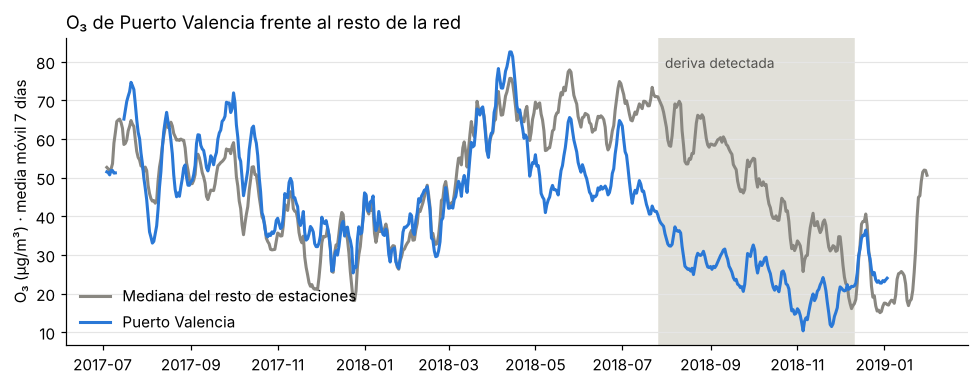

In [18]:
o3 = pd.read_sql_query("""SELECT estacion, fecha, media FROM medias_diarias
                           WHERE contaminante = 'O3' AND n_horas >= 18""", conn, parse_dates=["fecha"])
w = o3.pivot(index="fecha", columns="estacion", values="media").loc["2017-07-01":"2019-01-31"]
resto = w.drop(columns="Puerto Valencia").median(axis=1).rolling(7, min_periods=4).mean()
pv = w["Puerto Valencia"].rolling(7, min_periods=4).mean()
ep = inc[(inc.regla == "deriva_regional")].iloc[0]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axvspan(pd.Timestamp(ep.inicio), pd.Timestamp(ep.fin), color="#e1e0d9", zorder=0)
ax.plot(resto.index, resto, color="#898781", lw=2, label="Mediana del resto de estaciones")
ax.plot(pv.index, pv, color=AZUL, lw=2, label="Puerto Valencia")
ax.text(pd.Timestamp(ep.inicio) + pd.Timedelta(days=4), ax.get_ylim()[1] * 0.95,
        "deriva detectada", va="top", fontsize=9, color="#52514e")
ax.set_ylabel("O₃ (µg/m³) · media móvil 7 días")
ax.set_title("O₃ de Puerto Valencia frente al resto de la red", loc="left")
ax.grid(axis="y", color="#e5e5e5"); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

#### Impacto de excluir los datos sospechosos

Indicadores de toda la red, con y sin las horas excluibles (en el dashboard, el interruptor *"Excluir datos sospechosos"*):

In [19]:
filas_imp = []
for c in ["PM2.5", "PM10", "NO2", "O3"]:
    fila = {"contaminante": c}
    for ex, etiqueta in [(False, "todos"), (True, "sin sospechosos")]:
        diario = db.daily_means(conn, c, estaciones, d0, d1, excluir_qc=ex)
        horario = db.hourly_values(conn, c, estaciones, d0, d1, excluir_qc=ex) if c == "O3" else None
        ind = daily_indicator(c, diario, horario)
        fila[f"media ({etiqueta})"] = round(ind["valor"].mean(), 2)
        fila[f"% días > guía ({etiqueta})"] = round(100 * (ind["valor"] > GUIAS_OMS[c]["valor"]).mean(), 1)
    filas_imp.append(fila)
pd.DataFrame(filas_imp).set_index("contaminante")

,media (todos),% días > guía (todos),media (sin sospechosos),% días > guía (sin sospechosos)
contaminante,,,,
PM2.5,11.72,25.4,11.92,26.0
PM10,18.34,3.7,18.41,3.7
NO2,24.26,41.3,24.38,41.5
O3,70.94,8.1,71.29,8.2


**Lectura.** El efecto global es pequeño, porque se marca menos del 0,5 % de las mediciones, pero **va siempre en la misma dirección: al excluir, las medias y las superaciones suben**. Los valores atascados casi siempre lo están en el mínimo (1,0), así que hacían que el aire pareciera más limpio de lo que es. A nivel de estación el efecto es mayor: en Puerto Valencia el periodo con deriva rebajaba su media de O₃ de 2018.

**Integración:**
- `aire/calidad.py`: las tres reglas como funciones puras sobre el DataFrame largo, más `detectar()`.
- `aire/db.py`: la tabla `incidencias_calidad`, la vista `medias_diarias_qc` y el parámetro `excluir_qc` en las consultas, que añade un `NOT EXISTS` sobre las incidencias.
- `aire/etl.py`: el ETL detecta las incidencias en cada carga, las guarda y las resume en el log.
- `app.py`: el interruptor *"Excluir datos sospechosos (N h en esta selección)"*, desactivado si no hay nada que excluir, y el desplegable *"Control de calidad"* con las incidencias de la selección.

**Verificación.** `tests/test_calidad.py` incluye 7 tests: racha detectada, rachas cortas y huecos ignorados, CO y SO₂ excluidos de la regla, pico aislado como aviso, episodio de 3 h no marcado, deriva sintética de 60 días detectada en las fechas correctas, y carga y exclusión de extremo a extremo en SQLite. En total hay 26 tests y `ruff` pasa sin errores. El dashboard se ha probado con `streamlit.testing`.

### Mejora 3 · Efecto del confinamiento de 2020

**Pregunta.** ¿Cuánto bajó la contaminación durante el confinamiento? Y, sobre todo, ¿cuánto de esa bajada se debe al confinamiento y no a otras causas?

**Fechas** (Comunitat Valenciana): estado de alarma desde el **14/03/2020**; permiso retribuido recuperable ("**hibernación**", solo trabajadores esenciales) del 30/03 al 09/04; **fase 1** el 18/05; **fase 2** el 01/06; **fase 3** el 15/06; **nueva normalidad** desde el 21/06.

**Método** (`aire/confinamiento.py`). Cada paso responde a un problema concreto encontrado al explorar los datos:

| Paso | Qué hace | Por qué |
|---|---|---|
| 1. Misma época | Compara cada fase de 2020 con las mismas fechas de 2016–2019 | La contaminación tiene un ciclo anual muy marcado |
| 2. Mismas estaciones | Solo estaciones con datos en 2020 y en ≥ 3 años de referencia | La red cambia (el puerto, Valencia Centro desde 2018) |
| 3. Datos limpios | Usa `excluir_qc=True` (Mejora 2) | Los valores atascados en 1,0 simularían caídas |
| 4. Diferencia en diferencias | Efecto = log(2020/ref) en la fase − log(2020/ref) del 1 ene al 13 mar | **El NO₂ ya estaba un 20 % bajo antes del 14 de marzo**: sin el ajuste, esa caída se atribuiría al confinamiento |
| 5. Año normal | Repite el cálculo con cada año de referencia frente a los demás | Da el rango de variación de un año cualquiera |
| 6. Placebo 2021 | Repite el análisis como si el confinamiento hubiera sido en 2021 | Si 2021 también mostrara el efecto, no sería del confinamiento |
| 7. Veredicto | "Claro" solo si la variación bruta **y** la ajustada salen del rango normal, todas las estaciones van en el mismo sentido y el placebo no muestra nada parecido | Exigir las dos medidas protege de un periodo previo anómalo (la calima de febrero de 2020 en las partículas) |

La **nueva normalidad** (junio a diciembre) se muestra solo como **descriptiva**. En las primeras pruebas salía como efecto "claro" en partículas y O₃, pero el placebo reveló que en 2021 los niveles seguían igual de bajos: es un descenso persistente, no un efecto del confinamiento.

In [20]:
from aire import confinamiento as cf

tablas = []
for c in ["NO2", "PM10", "PM2.5", "O3"]:
    diario = db.daily_means(conn, c, estaciones, "2016-01-01", "2021-12-31", excluir_qc=True)
    r = cf.resumen(diario).assign(contaminante=c)
    tablas.append(r)
conf_tabla = pd.concat(tablas)
(conf_tabla.set_index(["contaminante", "fase"])
 [["n_estaciones", "variacion_bruta", "efecto", "efecto_min", "efecto_max",
   "normal_min", "normal_max", "placebo_efecto", "veredicto"]]
 .round(0))

n_estaciones  variacion_bruta  efecto  \
contaminante fase                                                      
NO2          Confinamiento                6            -69.0   -61.0   
             Hibernación                  6            -71.0   -64.0   
             Desescalada                  6            -49.0   -36.0   
             Nueva normalidad             6            -31.0   -13.0   
PM10         Confinamiento                3            -34.0   -44.0   
             Hibernación                  3            -17.0   -30.0   
             Desescalada                  3            -29.0   -40.0   
             Nueva normalidad             3            -39.0   -48.0   
PM2.5        Confinamiento                3             -9.0   -36.0   
             Hibernación                  3             23.0   -13.0   
             Desescalada                  3            -29.0   -50.0   
             Nueva normalidad             3            -30.0   -51.0   
O3           Confinamiento                6             -1.0    25.0   
             Hibernación                  6             14.0    43.0   
             Desescalada                  6              6.0    34.0   
             Nueva normalidad             6             13.0    42.0   

                               efecto_min  efecto_max  normal_min  normal_max  \
contaminante fase                                                               
NO2          Confinamiento          -70.0       -48.0       -38.0        36.0   
             Hibernación            -77.0       -39.0       -45.0        76.0   
             Desescalada            -52.0       -19.0       -39.0        53.0   
             Nueva normalidad       -25.0         8.0       -39.0        21.0   
PM10         Confinamiento          -54.0       -32.0       -16.0        22.0   
             Hibernación            -44.0       -12.0       -28.0        34.0   
             Desescalada            -57.0       -13.0       -30.0        45.0   
             Nueva normalidad       -65.0       -37.0       -41.0        80.0   
PM2.5        Confinamiento          -42.0       -26.0       -16.0        29.0   
             Hibernación            -17.0        -6.0       -11.0        26.0   
             Desescalada            -56.0       -46.0       -35.0        64.0   
             Nueva normalidad       -62.0       -44.0       -41.0        38.0   
O3           Confinamiento           16.0        41.0       -19.0        21.0   
             Hibernación             30.0        56.0       -26.0        25.0   
             Desescalada             12.0        65.0       -21.0        17.0   
             Nueva normalidad        22.0        56.0       -23.0        22.0   

                               placebo_efecto       veredicto  
contaminante fase                                              
NO2          Confinamiento               15.0           claro  
             Hibernación                 33.0           claro  
             Desescalada                 15.0  no concluyente  
             Nueva normalidad            21.0     descriptiva  
PM10         Confinamiento                3.0  no concluyente  
             Hibernación                 26.0  no concluyente  
             Desescalada                -22.0  no concluyente  
             Nueva normalidad            -2.0     descriptiva  
PM2.5        Confinamiento               -4.0  no concluyente  
             Hibernación                 26.0  no concluyente  
             Desescalada                -31.0  no concluyente  
             Nueva normalidad           -26.0     descriptiva  
O3           Confinamiento              -16.0  no concluyente  
             Hibernación                -16.0  no concluyente  
             Desescalada                -17.0  no concluyente  
             Nueva normalidad           -10.0     descriptiva

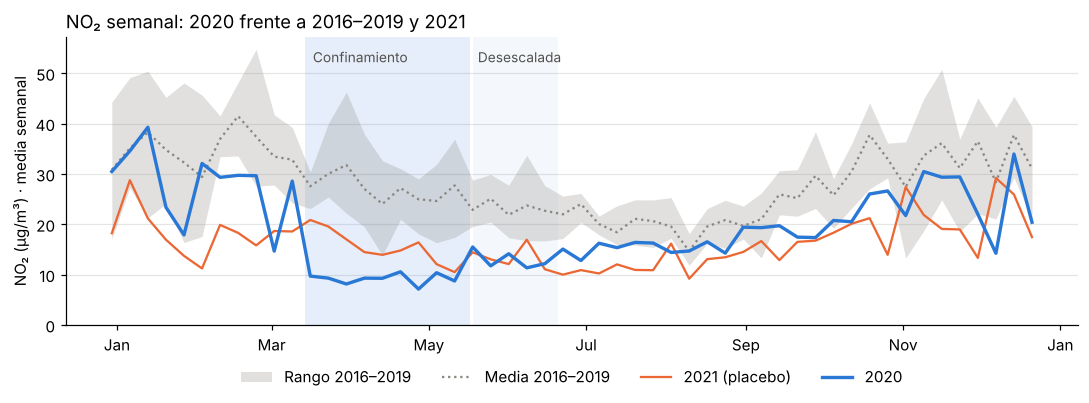

In [21]:
diario_no2 = db.daily_means(conn, "NO2", estaciones, "2016-01-01", "2021-12-31", excluir_qc=True)
s20, s21 = cf.serie_semanal(diario_no2, 2020), cf.serie_semanal(diario_no2, 2021)
x = [pd.Timestamp.fromisocalendar(2020, int(w), 1) for w in s20["semana"]]
x21 = [pd.Timestamp.fromisocalendar(2020, int(w), 1) for w in s21["semana"]]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axvspan(pd.Timestamp("2020-03-14"), pd.Timestamp("2020-05-17"), color=AZUL, alpha=0.12, lw=0)
ax.axvspan(pd.Timestamp("2020-05-18"), pd.Timestamp("2020-06-20"), color=AZUL, alpha=0.05, lw=0)
ax.fill_between(x, s20["ref_min"], s20["ref_max"], color="#898781", alpha=0.25, lw=0, label="Rango 2016–2019")
ax.plot(x, s20["ref_media"], color="#898781", lw=1.5, ls=":", label="Media 2016–2019")
ax.plot(x21, s21["anio_valor"], color="#eb6834", lw=1.5, label="2021 (placebo)")
ax.plot(x, s20["anio_valor"], color=AZUL, lw=2.2, label="2020")
ax.text(pd.Timestamp("2020-03-17"), ax.get_ylim()[1] * 0.96, "Confinamiento", fontsize=9, color="#52514e", va="top")
ax.text(pd.Timestamp("2020-05-20"), ax.get_ylim()[1] * 0.96, "Desescalada", fontsize=9, color="#52514e", va="top")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
ax.set_ylabel("NO₂ (µg/m³) · media semanal"); ax.set_ylim(bottom=0)
ax.set_title("NO₂ semanal: 2020 frente a 2016–2019 y 2021", loc="left")
ax.grid(axis="y", color="#e5e5e5"); ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()

**¿Pudo la meteorología explicar la caída?** El CSV trae variables meteorológicas que el ETL no carga. Aquí se comparan las de la ventana del confinamiento (14 mar–17 may) en cada año:

In [22]:
met = pd.DataFrame({
    "fecha": fecha,                                         # fechas ya corregidas (apartado 4.1)
    "viento (m/s)": etl._to_number(raw["Velocidad del viento"]),
    "temperatura (°C)": etl._to_number(raw["Temperatura"]),
    "horas con lluvia (%)": etl._to_number(raw["Precipitacion"]).gt(0).astype(float) * 100,
})
md_ = met["fecha"].dt.strftime("%m-%d")
ventana = met[(md_ >= "03-14") & (md_ <= "05-17") & met["fecha"].dt.year.le(2021)]
ventana.groupby(ventana["fecha"].dt.year).mean(numeric_only=True).round(2).T

fecha,2016,2017,2018,2019,2020,2021
viento (m/s),2.74,2.05,3.06,2.92,2.01,1.98
temperatura (°C),15.55,15.75,15.53,16.46,15.8,15.11
horas con lluvia (%),1.63,1.54,1.79,5.73,6.62,4.6


**Resultados:**

| Contaminante | Confinamiento | Hibernación | Veredicto | Lectura |
|---|---:|---:|---|---|
| **NO₂** | **−61 %** | **−64 %** | ✅ **claro** | Las 6 estaciones bajan entre un 48 y un 70 %; en un año normal la variación va de −38 a +36 %; el placebo 2021 da +15 %. En la desescalada (−36 %) ya está dentro del rango normal. |
| **PM10** | −44 % | −30 % | ➖ no concluyente | Solo 3 estaciones, la variación bruta (−34 %) está dentro de lo normal, y llovió más que otros años. |
| **PM2.5** | −36 % | −13 % | ➖ no concluyente | La variación bruta es de solo −9 %: el ajuste "crea" la caída porque el periodo previo tuvo la calima de febrero. |
| **O₃** | +25 % | +43 % | ➖ no concluyente | En bruto apenas cambia (−1 %; +14 % en la hibernación). Una subida encajaría con la química, porque con menos NO de los coches se destruye menos ozono, pero no sale del rango normal. |

**Meteorología.** Durante el confinamiento de 2020 el viento fue **de los más flojos** de la serie: 2,0 m/s, como en 2017, frente a 2,7–3,1 en 2016, 2018 y 2019 (media de 2016–2019: 2,7). Con menos viento el NO₂ se dispersa peor y suele subir, así que la caída del NO₂ se produjo **a pesar** de la meteorología y la estimación es conservadora. También fue la primavera con más horas de lluvia, que sí ayuda a bajar las partículas: es otra razón para no atribuir al confinamiento la caída de PM.

**Conclusión.** El confinamiento redujo el NO₂ (el contaminante más ligado al tráfico) en torno a un **60 %** en València, un efecto muy por encima de la variación entre años y que no aparece en 2021. Para las partículas y el ozono, los datos no permiten afirmar un efecto. Que el análisis diga "no concluyente" donde no hay evidencia también es un resultado.

**Hallazgos que salieron por el camino:**
- **Hay un descenso persistente desde 2020.** En 2021, el NO₂ y las partículas siguen entre un 30 % y un 40 % por debajo de 2016–2019 durante todo el año (se ve en la línea naranja). Podría deberse a cambios de movilidad, a una tendencia de fondo o a cambios en los equipos. No se investiga aquí.
- **El primer veredicto automático era demasiado optimista.** Daba "claro" en partículas y O₃ hasta que se añadieron la exigencia de que coincidan las dos medidas y la prueba placebo.

**Integración:**
- `aire/confinamiento.py`: `resumen()`, `efecto_por_estacion()` y `serie_semanal()`, con el método documentado.
- `pages/1_Confinamiento_2020.py`: una página nueva del dashboard (Streamlit la muestra en la barra lateral). Tiene selector de contaminante, indicadores con el efecto ajustado y la variación bruta, el gráfico semanal con la opción de mostrar 2021 y la tabla por fases.
- `tests/test_confinamiento.py`: 6 tests con datos sintéticos de efecto conocido. Comprueban que se descuenta la tendencia previa, que el placebo anula el veredicto, que la nueva normalidad es descriptiva, que se excluyen las estaciones sin referencia y el caso sin datos de 2020. En total hay 32 tests.

## 6.4 Fase 4 · Preparación para publicar

**Problema.** `data/` no está en GitHub (48 MB de CSV y 175 MB de base de datos), así que una app desplegada desde el repositorio arrancaría sin datos.

**Opciones consideradas:**

| Opción | Ventajas | Inconvenientes |
|---|---|---|
| Descargar el CSV oficial al arrancar y ejecutar el ETL | Siempre usa la fuente original | Depende de que el portal esté disponible; cada arranque en frío tarda 30–60 s |
| Subir `aire.db` | Arranque inmediato | 175 MB: supera el límite de 100 MB por archivo de GitHub |
| **Subir un extracto Parquet de las mediciones limpias** ✅ | ~5 MB, sin dependencias externas, arranque en ~20 s | Hay que regenerarlo si cambia el ETL |

**Implementación:**
- `aire/snapshot.py`: `export_snapshot()` (`python -m aire.snapshot`) guarda las mediciones limpias en `snapshot/mediciones.parquet`, con compresión zstd y columnas categóricas (**4,8 MB** para 1,6 millones de mediciones). Se mantiene `float64` porque con `float32` el valor 0,1 pasaría a ser 0,100000001 y fallaría la detección de valores atascados. `build_db_from_snapshot()` reconstruye la base, recalcula el control de calidad y la escribe primero en un archivo temporal que luego renombra: así nunca queda una base a medio crear si el proceso se corta.
- `aire/app_utils.py`: `preparar_datos()` se ejecuta una sola vez por servidor (`st.cache_resource`) y muestra el aviso *"Preparando los datos (solo en el primer arranque)…"*.
- `app.py` pasa a ser el punto de entrada con `st.navigation`: la barra lateral muestra **Explorador** y **Confinamiento 2020** en lugar del nombre del archivo ("app"). Las páginas están en `paginas/`.
- En la página del confinamiento, la variación bruta aparece como texto bajo los indicadores. Antes se mostraba como "delta" de `st.metric`, con una flecha hacia arriba engañosa en una variación negativa.
- La licencia de los datos (CC BY 4.0) permite redistribuirlos citando la fuente, que el dashboard muestra bajo el título.

**Verificación:**
- Simulación de la nube: con una copia limpia del repositorio, **sin `data/`** y solo con el extracto, el primer arranque tarda **~21 s**. Los indicadores son idénticos a los locales (NO₂: 26,1 µg/m³ de media; confinamiento: −61 %, efecto claro).
- `tests/test_snapshot.py`: comprueba la ida y vuelta base → Parquet → base (mediciones idénticas, sin archivo temporal residual) y `ensure_db` en sus tres casos. En total hay **34 tests**.
- Capturas del dashboard en `docs/`, enlazadas en el README.

**Pendiente:** publicar en Streamlit Community Cloud y añadir el enlace de la demo al README.

## 7. Limitaciones

- Datos hasta 2021: el dataset del portal termina ahí.
- Datos *no validados definitivamente* por la red: pueden diferir de los informes anuales oficiales.
- La comparación se hace con guías **diarias**; la OMS también fija guías anuales (p. ej. NO₂ 10 µg/m³, PM2.5 5 µg/m³) que serían aún más exigentes.

## 8. Próximos pasos

- **Fase 3 (completada).** Mejoras opcionales que quedan en el `ROADMAP.md`: `ruff` en el CI, correlación con la meteorología, predicción del NO₂ y estudio del descenso persistente desde 2020.
- **Fase 4:** publicar en Streamlit Community Cloud y enlazar la demo en el README (todo lo demás está preparado).

## 9. Registro de cambios

| Fecha | Fase | Cambio |
|---|---|---|
| 13/10/2026 | 0 | Base funcional: ETL, SQLite, dashboard Streamlit y tests con datos sintéticos |
| 13/10/2026 | 1 | Carga del dataset oficial RVVCCA 2016–2021 (1 598 639 mediciones) |
| 13/10/2026 | 1 | Paleta del dashboard ampliada a 10 colores (había 10 estaciones y solo 8 colores) |
| 13/10/2026 | 1 | Aviso en el README para borrar `aire.db` al pasar de datos sintéticos a reales |
| 13/10/2026 | 1 | `TransformReport`: desglose de descartes en el log del ETL y test asociado |
| 13/10/2026 | 1 | Este informe técnico (`Documentation.ipynb`) |
| 13/10/2026 | 1 | Revisión visual del dashboard con datos reales |
| 13/10/2026 | 1 | **Corrección de 162 096 fechas con día y mes intercambiados** (`_fix_day_month_swap`), validadas con el día de la semana, y test |
| 13/10/2026 | 1 | Base regenerada con las fechas corregidas y revisión visual confirmada contaminante a contaminante (cierre de la Fase 1) |
| 13/10/2026 | 1 | Gráfico de evolución diaria: corta la línea en los huecos y suaviza por días de calendario (`serie_diaria_continua`), con test |
| 13/10/2026 | 2 | Repositorio público en GitHub, primer `push` y CI de GitHub Actions en verde |
| 13/10/2026 | 2 | README con usuario real e insignia del CI; `.gitignore` ampliado; rutas relativas en los logs |
| 14/10/2026 | 3 | Mejora 1: la guía OMS se muestra como texto cuando supera en más de 3× los datos (CO, SO₂), con tests; eliminado un `import` sin usar en `app.py` |
| 14/10/2026 | 3 | Mejora 2: control de calidad de sensores (`aire/calidad.py`): valores atascados, picos aislados y deriva regional del O₃; tabla `incidencias_calidad`, opción de exclusión en el dashboard y 7 tests |
| 15/10/2026 | 3 | Mejora 3: efecto del confinamiento de 2020 (diferencia en diferencias, rango de un año normal y placebo 2021), página nueva del dashboard y 6 tests |
| 15/10/2026 | 4 | Extracto Parquet (`aire/snapshot.py`) y creación automática de la base al arrancar; navegación con `st.navigation` (páginas en `paginas/`); capturas en `docs/`; 2 tests |